# Figure S4 - Global conformational properties of DDX4<sup>[1-245]</sup> from all-atom simulations

**What the figure shows.** Two panels describing how the size and the shape of the chain co-vary across the all-atom ensemble.

* **(A)** A two-dimensional histogram of radius of gyration ($R_g$) against asphericity, with kernel density estimate contours overlaid for visual clarity.
* **(B)** The same, with the hydrodynamic radius ($R_h$) on the x-axis, and a vertical line marking the value measured experimentally by DLS (42 Angstroms).

**Reading the panels.** Asphericity measures how far a conformation departs from a sphere: 0 is perfectly spherical, 1 is a rod. Both panels show a single broad, diagonally elongated cloud - larger conformations are also more elongated, which is exactly what is expected of a well-sampled disordered chain exploring many conformations rather than a folded protein sitting in one. The breadth is the point: there is no dominant conformation.

**Why it matters for the paper.** The ensemble average $R_h$ is 44.0 Angstroms, in reasonable agreement with the 42 Angstroms measured by DLS for monomeric DDX4<sup>[1-245]</sup> under non-phase-separating conditions. That agreement is what licenses the use of these simulations to interpret the experimental measurements: the computational ensemble is the right size, and the vertical line in panel B lets you see that it sits comfortably inside the sampled distribution rather than at its edge.

Figure S5 is the same analysis applied to STARLING-derived ensembles, and should be read alongside this one.

**How it is made.** All-atom Monte Carlo simulations were run in CAMPARI with the ABSINTH implicit solvent model; $R_g$, $R_h$ and asphericity are computed here directly from the pooled trajectory with [SOURSOP](https://soursop.readthedocs.io/). $R_h$ uses SOURSOP's default Nygaard *et al.* estimator, the same approximation used in Figure S2 and discussed in Figure S8.

## What is in this directory

| path | contents |
|------|----------|
| `figures/` | output; the notebook writes one PDF and PNG per panel |

This figure has no data files of its own. It reads the CAMPARI DDX4 NTD trajectory (~350 MB) from the shared `data/` directory at the root of `perets_2025`, which is **not tracked by git** - see `../data/README.md` for what belongs there, how it was generated, and how to obtain it.

## Setup

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Holehouse lab figure defaults (December 2024)
# ---------------------------------------------------------------------------

# export PDF/PS fonts as TrueType so text stays editable in Illustrator/Affinity
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

matplotlib.rcParams['axes.linewidth'] = 0.5
matplotlib.rcParams['lines.linewidth'] = 0.8

matplotlib.rcParams['xtick.major.size'] = 2
matplotlib.rcParams['xtick.minor.size'] = 0.5
matplotlib.rcParams['ytick.major.size'] = 2
matplotlib.rcParams['ytick.minor.size'] = 0.5
matplotlib.rcParams['xtick.major.width'] = 0.375
matplotlib.rcParams['ytick.major.width'] = 0.375
matplotlib.rcParams['xtick.minor.width'] = 0.375
matplotlib.rcParams['ytick.minor.width'] = 0.375
matplotlib.rcParams['xtick.major.pad'] = 1
matplotlib.rcParams['ytick.major.pad'] = 1

matplotlib.rcParams['xtick.labelsize'] = 8
matplotlib.rcParams['ytick.labelsize'] = 8
matplotlib.rcParams['axes.labelsize'] = 10
matplotlib.rcParams['legend.fontsize'] = 8

# The manuscript figures used Arial; the fallbacks let this run anywhere.
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from soursop.sstrajectory import SSTrajectory

In [2]:
import os

TRAJ_DIR = os.environ.get('PERETS_DATA_DIR', '../data')
CAMPARI_NTD = os.path.join(TRAJ_DIR, 'campari', 'ddx4_ntd')

os.makedirs('figures', exist_ok=True)

status = 'found' if os.path.isfile(os.path.join(CAMPARI_NTD, 'full.xtc')) else 'MISSING - see ../data/README.md'
print(f'DDX4 NTD  {CAMPARI_NTD}  [{status}]')

DDX4 NTD  ../data/campari/ddx4_ntd  [found]


## Load the ensemble and compute the three properties

The asphericity calculation builds the gyration tensor for every frame and is the slowest step here, though it still only takes a few seconds. `get_hydrodynamic_radius` uses SOURSOP's default `mode='nygaard'`.

In [3]:
NTD = SSTrajectory(f'{CAMPARI_NTD}/full.xtc', f'{CAMPARI_NTD}/full.pdb').proteinTrajectoryList[0]

print(f'{NTD.n_frames:,} conformers, {NTD.n_residues} residues (245 + 2 terminal caps)')

25,000 conformers, 247 residues (245 + 2 terminal caps)


In [4]:
rg = NTD.get_radius_of_gyration()
rh = NTD.get_hydrodynamic_radius()      # default mode='nygaard'
asph = NTD.get_asphericity()

print(f'Rg          : mean {np.mean(rg):.2f} A   range {np.min(rg):.1f} - {np.max(rg):.1f}')
print(f'Rh          : mean {np.mean(rh):.2f} A   range {np.min(rh):.1f} - {np.max(rh):.1f}   (DLS: 42 A)')
print(f'asphericity : mean {np.mean(asph):.3f}  range {np.min(asph):.2f} - {np.max(asph):.2f}')

STATUS: Computing gyration tensor for 25000 frames


Rg          : mean 45.89 A   range 28.4 - 92.5
Rh          : mean 44.04 A   range 33.2 - 61.2   (DLS: 42 A)
asphericity : mean 0.370  range 0.00 - 0.91


## The panels

Both panels are built the same way: a 75x75 two-dimensional histogram in absolute counts (not a density, so the colourbar is directly interpretable as "how many conformations landed in this bin"), with seaborn KDE contours drawn on top purely as a visual guide to the shape of the distribution.

In [5]:
# white -> navy, so that empty bins vanish into the background
white_to_blue = LinearSegmentedColormap.from_list('white_to_blue', ['white', 'navy'])


def density_contour_panel(x, y, xlabel, outfile, experimental_value=None):
    """
    Draw a 2D histogram of two conformational properties with KDE contours.

    Produces one panel of Figure S4: absolute-count hexless 2D histogram with
    kernel density estimate contours overlaid for visual clarity, and an
    optional vertical line marking an experimentally measured value.

    Parameters
    ----------
    x : numpy.ndarray
        Per-conformer values for the x-axis (a radius, in Angstroms).

    y : numpy.ndarray
        Per-conformer values for the y-axis (asphericity).

    xlabel : str
        Axis label for the x-axis.

    outfile : str
        Path stem (without extension) the panel is written to; both a PDF and
        a PNG are saved.

    experimental_value : float or None
        If given, a vertical line is drawn here and labelled as the
        experimental DLS measurement. Default = None.

    Returns
    -------
    None
    """

    fig, ax = plt.subplots(figsize=(4.5, 4))

    # absolute counts, so the colourbar means something concrete
    hb = ax.hist2d(x, y, bins=75, cmap=white_to_blue, density=False)

    # contours are a visual guide only - they carry no extra information
    sns.kdeplot(x=x, y=y, levels=12, linewidths=0.3, color='k', ax=ax)

    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel('Asphericity', fontsize=12)

    cbar = fig.colorbar(hb[3], ax=ax)
    cbar.set_label('Count', fontsize=12)

    if experimental_value is not None:
        ax.axvline(experimental_value, color='k', lw=1.3, ls='-',
                   label='Experimental value (DLS)')
        ax.legend(frameon=False)

    ax.set_facecolor('white')
    fig.patch.set_facecolor('white')
    ax.tick_params(labelsize=10)
    plt.tight_layout()

    plt.savefig(f'{outfile}.pdf')
    plt.savefig(f'{outfile}.png', dpi=350)
    plt.show()

### Panel A - radius of gyration versus asphericity

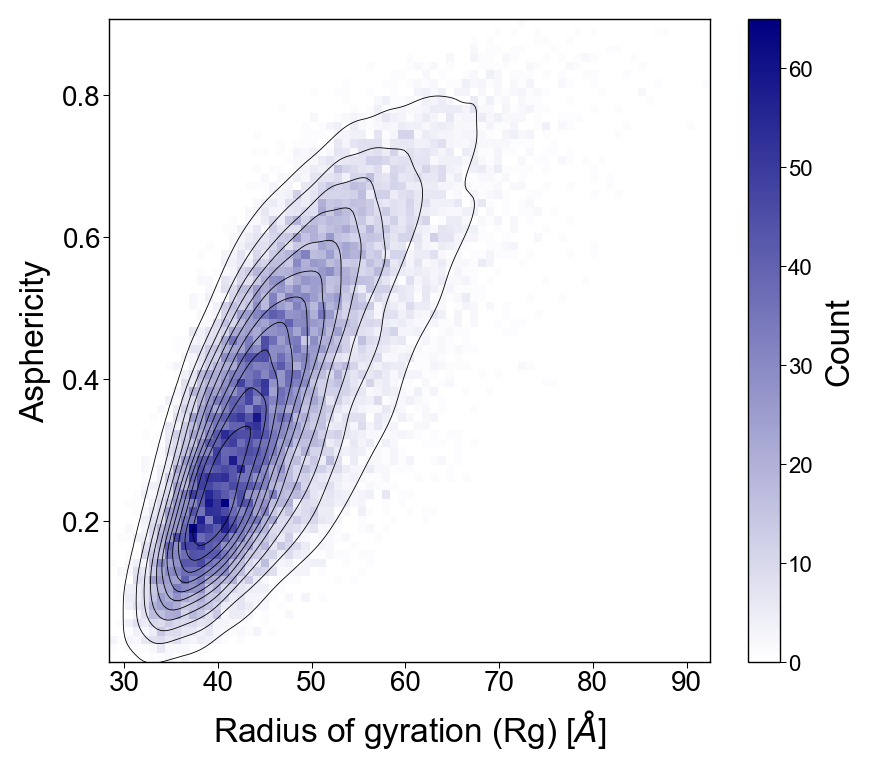

mean Rg = 45.9 A


In [6]:
density_contour_panel(rg, asph,
                      xlabel='Radius of gyration (Rg) [$\\AA$]',
                      outfile='figures/figure_S4A_rg_asphericity')

print(f'mean Rg = {np.mean(rg):.1f} A')

### Panel B - hydrodynamic radius versus asphericity

The vertical line is the DLS measurement of 42 Angstroms.

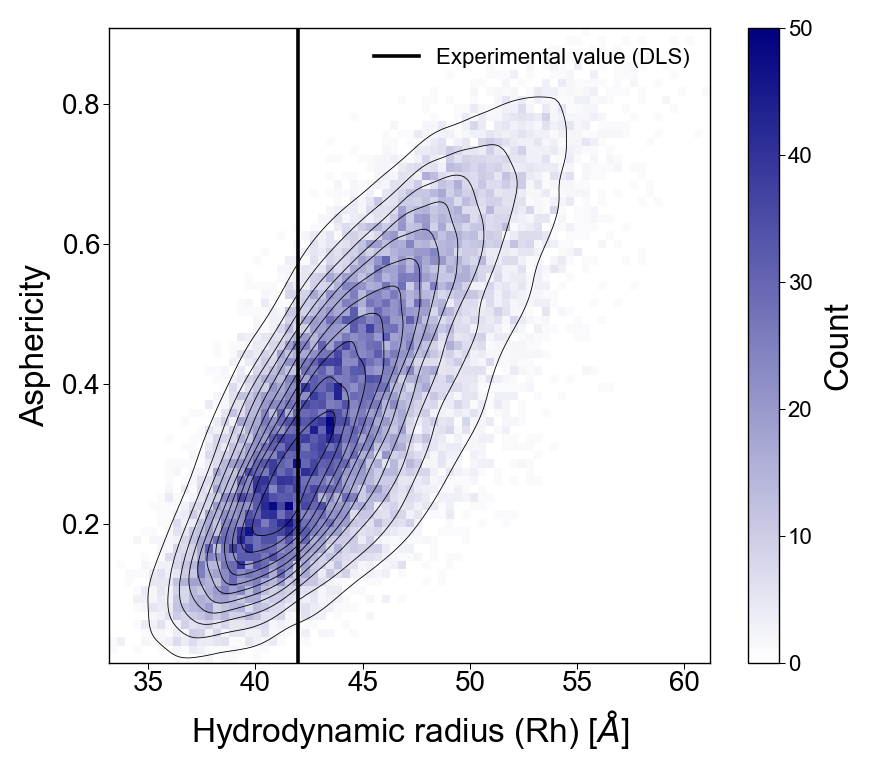

mean Rh = 44.04 A   (experimental, DLS: 42 A)


In [7]:
density_contour_panel(rh, asph,
                      xlabel='Hydrodynamic radius (Rh) [$\\AA$]',
                      outfile='figures/figure_S4B_rh_asphericity',
                      experimental_value=42)

print(f'mean Rh = {np.mean(rh):.2f} A   (experimental, DLS: 42 A)')

## Differences from the published figure

* **Assembly and labelling.** The published Figure S4 was assembled in a vector graphics editor from the two panel exports; the A and B letters were added there.
* **The DLS marker in panel B.** The published panel shows the experimental value as a dashed line with the label placed above the axes. The raw export - and this notebook - draws it as a solid line with an in-axes legend.
* **Ensemble size.** The trajectory analysed here contains 25,000 conformers, which matches the published caption for this figure. Note that the *Materials and methods* section quotes a final ensemble of 23,773 conformers; the pooled trajectory distributed with this repository is the 25,000-conformer version the figure was made from.
* **Shared code between the panels.** The original notebook had the plotting code written out twice, once per panel. Here it is a single function called twice, which is why the two panels are guaranteed to be styled identically.